# CSS 布局

浮动（前端第06天，CSS第04天）


本篇接着盒子模型学习：先按元素在 HTML 中的位置选中它，再用伪元素生成辅助内容，最后用浮动完成水平布局，并处理浮动对后续内容的影响。

资料来自 `day06.rar` 中的 `day06（CSS04-浮动）v1.0.pdf`（41页）、课堂 HTML、`CSS第04天（浮动）总结.xmind`、必做与选做资料。按原课顺序整理，保留教学原图和实际代码。注释与当前代码不一致、设计图与源码有差异的地方，在对应案例旁说明。

本日目标：会用结构伪类查找元素，认识标准流与浮动的排列特点，完成小米模块和网页导航，理解父盒子为什么会失去高度，并能使用课程中的五种方法清除浮动影响。

代码用于阅读。课堂示例摘录 `<style>` 与 `<body>`，练习时放回对应 HTML 文件；必做案例和微金所保留完整 HTML。图片已嵌入笔记，代码中的素材路径仍以原案例文件夹为准。


## 1. 结构伪类选择器

结构伪类根据元素与兄弟元素的位置关系进行选择。列表中第一个、最后一个、每行末尾等位置可以直接通过选择器表达，减少为这些位置额外添加类名的需要。


### 1.1 第一个、最后一个、第几个与倒数第几个

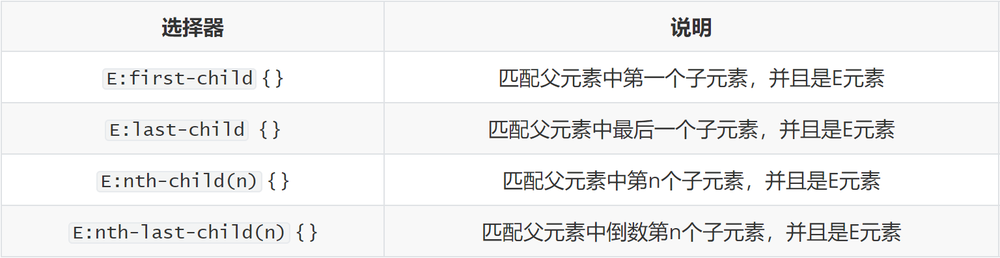

| 写法 | 匹配条件 |
| --- | --- |
| `E:first-child` | 元素是父级的第一个元素子节点，并且标签为 `E` |
| `E:last-child` | 元素是父级的最后一个元素子节点，并且标签为 `E` |
| `E:nth-child(n)` | 元素是父级的第 `n` 个元素子节点，并且标签为 `E` |
| `E:nth-last-child(n)` | 从最后向前数，元素排第 `n`，并且标签为 `E` |

**序号从1开始，位置在各自父元素的子元素中计算。** 不是把整页相同标签排成一列计数。

补充：这里计数的是元素节点，源码的空格、换行、文字和注释不占一个元素序号。结构伪类在上一天的权重元组中计入“类选择器”这一位，例如 `li:first-child` 的权重为 `(0, 0, 1, 1)`。

文件：`01-案例/01-选择器-结构伪类.html`。

CSS（放在 `<style>` 内）：

```css
/* 选中第一个 */
/* li:first-child {
    background-color: green;
} */

/* 最后一个 */
/* li:last-child {
    background-color: green;
} */

/* 任意一个 */
/* li:nth-child(5) {
    background-color: green;
} */

/* 倒数第xx个 */
li:nth-last-child(1) {
    background-color: blue;
}
```

HTML（放在 `<body>` 内）：

```html
<!-- ul>li{这是第$个li}*8 -->
<ul>
    <li>这是第1个li</li>
    <li>这是第2个li</li>
    <li>这是第3个li</li>
    <li>这是第4个li</li>
    <li>这是第5个li</li>
    <li>这是第6个li</li>
    <li>这是第7个li</li>
    <li>这是第8个li</li>
</ul>
```

当前只有 `li:nth-last-child(1)` 启用，因此第8个 `li` 的背景为蓝色。前三种写法已被注释；练习时一次启用一种，分别观察第1个、第8个、第5个以及倒数第1个的位置。


### 1.2 用公式选出一组元素

括号中除了具体序号，还可以使用含 `n` 的公式。课程中 `n` 依次取 `0、1、2、3……`；公式产生的结果只有对应到实际存在的正序号时才会匹配。

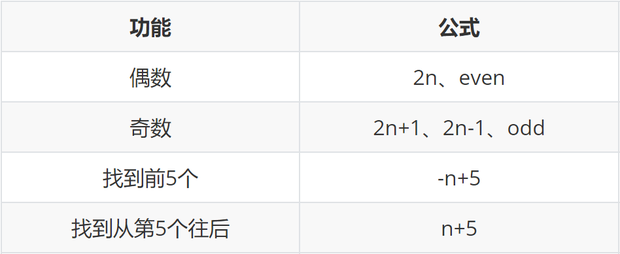

| 要选择的位置 | 写法 | 有效序号示例 |
| --- | --- | --- |
| 偶数 | `:nth-child(2n)` 或 `:nth-child(even)` | 2、4、6、8…… |
| 奇数 | `:nth-child(2n+1)`、`:nth-child(2n-1)` 或 `:nth-child(odd)` | 1、3、5、7…… |
| 前5个 | `:nth-child(-n+5)` | 5、4、3、2、1，最终匹配第1至5个 |
| 第5个及以后 | `:nth-child(n+5)` | 5、6、7、8…… |
| 前3个 | `:nth-child(-n+3)` | 1、2、3 |
| 4的倍数 | `:nth-child(4n)` | 4、8、12…… |

`2n` 在 `n=0` 时得到0，`2n-1` 在 `n=0` 时得到-1，它们都不会选中一个“第0个”或“第-1个”元素。`-n+5` 则从5递减到1，再往后的0和负数不匹配。

文件：`01-案例/02-选择器-结构伪类-公式.html`。

CSS（放在 `<style>` 内）：

```css
/* ** 偶数 */
/* li:nth-child(2n) { */

    /* *** 奇数 */
/* li:nth-child(2n+1) { */
    /* 找到前3个 */
/* li:nth-child(-n+3) { */

    /* *** 4的倍数 */
li:nth-child(4n) {
    background-color: green;
}
```

HTML（放在 `<body>` 内）：

```html
<ul>
    <li>这是第1个li</li>
    <li>这是第2个li</li>
    <li>这是第3个li</li>
    <li>这是第4个li</li>
    <li>这是第5个li</li>
    <li>这是第6个li</li>
    <li>这是第7个li</li>
    <li>这是第8个li</li>
</ul>
```

当前启用 `4n`，8个列表项中的第4、8个背景为绿色。其他公式是注释中的替换方案。后面小米模块用 `4n` 清除每行最后一张卡片的右外边距，用 `n+5` 清除第二排的下外边距。


### 1.3 易错点：先确定在谁的孩子中计数

课件示例是多个 `li`，每个 `li` 内都有一个 `a`：

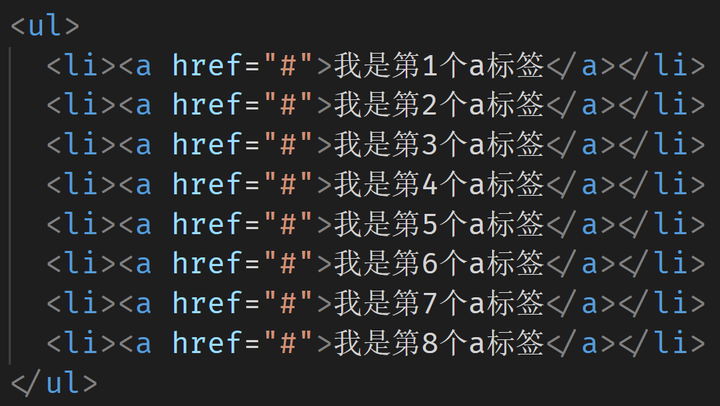

如果直接写 `a:first-child`，它判断的是“这个 `a` 是不是自己父元素的第一个孩子”。每个 `li` 中唯一的 `a` 都符合，所以会选中多个链接。

要找第一个 `li` 里的链接，应先选中第一个 `li`，再找其中的 `a`：

```css
li:first-child a {
    color: red;
}
```

这段写法也是 `01-案例/03-案例-结构伪类.html` 中第一个 `<style>` 的方案，不过该 `<style>` 整体已被 HTML 注释包住。文件当前启用的是第二个 `<style>`，需求进一步变成“第一个 `li` 中的第3个 `a`”：

CSS（放在 `<style>` 内）：

```css
/* 找到第一个li 里面的  第三个a  设置文字颜色是红色 */
li:first-child a:nth-child(3) {
    color: red;
}
```

HTML（放在 `<body>` 内）：

```html
<ul>
    <li>
        <a href="#">这是第1个li里面的a1</a>
        <a href="#">这是第1个li里面的a2</a>
        <!-- 选中第三个a -->
        <a href="#">这是第1个li里面的a3</a>
        <a href="#">这是第1个li里面的a4</a>
        <a href="#">这是第1个li里面的a5</a>
    </li>
    <li><a href="#">这是第2个li里面的a</a></li>
    <li><a href="#">这是第3个li里面的a</a></li>
    <li><a href="#">这是第4个li里面的a</a></li>
    <li><a href="#">这是第5个li里面的a</a></li>
    <li><a href="#">这是第6个li里面的a</a></li>
    <li><a href="#">这是第7个li里面的a</a></li>
    <li><a href="#">这是第8个li里面的a</a></li>
</ul>
```

当前只有文字“这是第1个li里面的a3”为红色。先通过 `li:first-child` 缩小到第一个列表项，再通过 `a:nth-child(3)` 匹配它的第3个元素子节点。这里前面都是 `a`，所以恰好也是第3个链接；如果插入其他标签，需要重新判断所有元素子节点的序号。


### 1.4 了解：nth-child 与 nth-of-type

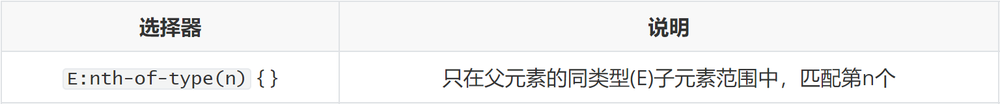

`E:nth-child(n)` 先在所有同级元素子节点中计数，再检查当前位置的元素是否为 `E`。

`E:nth-of-type(n)` 则在同级、同标签类型的元素中计数。这里的“类型”指标签名，不是类名。

补充示例，用混合标签说明课件中的区别：

```html
<div>
    <h2>标题</h2>
    <p>段落A</p>
    <p>段落B</p>
</div>
```

```css
p:nth-child(2) {
    color: red;
}

p:nth-of-type(2) {
    background-color: pink;
}
```

`p:nth-child(2)` 选中段落A，因为它是所有孩子中的第2个；`p:nth-of-type(2)` 选中段落B，因为它是 `p` 这一类型中的第2个。即使给两个段落不同的 `class`，也不会改变 `nth-of-type` 的计数分组。


## 2. 伪元素

伪元素通过 CSS 模拟出内容和盒子的效果。原课用它处理页面中的非主体内容；本日后面还会用它生成清除浮动的辅助盒子。


### 2.1 before、after 的位置与必需属性

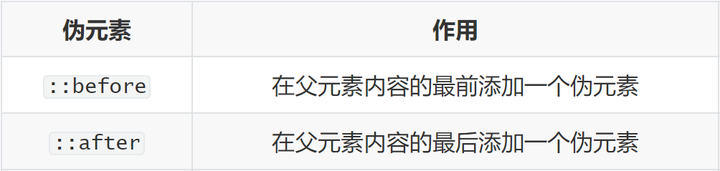

| 伪元素 | 出现的位置 |
| --- | --- |
| `E::before` | `E` 内部，原有内容的最前面 |
| `E::after` | `E` 内部，原有内容的最后面 |

“前面”和“后面”说的是**元素内部的内容顺序**，不是在它的外面创建一个兄弟标签。HTML 元素由标签定义；伪元素由 CSS 产生相应效果，不会真的向 HTML DOM 中插入一个普通标签。

伪元素必须设置 `content` 才能产生内容效果；没有文字时也要写空字符串 `content: '';`。本课的 `::before`、`::after` 默认按行内盒子显示，直接设置宽高不能得到需要的块状尺寸，需配合 `display` 等处理。

XMind 提到旧版浏览器曾使用单冒号形式。本篇沿用课件的 CSS3 双冒号写法，伪类如 `:first-child` 与伪元素如 `::before` 注意区分。


### 2.2 课堂示例：把伪元素显示成一个方块

课件的示意效果如下，用橙色小块表现伪元素：

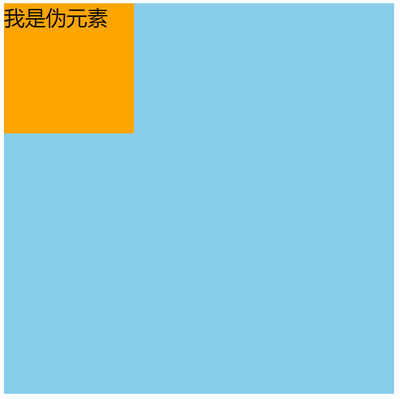

课堂文件 `01-案例/04-选择器-伪元素.html` 使用了另一组颜色和内容，当前源码如下：

CSS（放在 `<style>` 内）：

```css
.father {
    width: 300px;
    height: 300px;
    background-color: pink;
}

.father::before {
    /* 内容 */
    /* content属性必须添加, 否则伪元素不生效 */
    content: '';
    color: green;
    width: 100px;
    height: 100px;
    background-color: blue;

    /* 默认是行内元素, 宽高不生效 */
    display: block;
}

.father::after {
    content: '大米';
}
```

HTML（放在 `<body>` 内）：

```html
<!-- 伪元素 通过css创建标签, 装饰性的不重要的小图 -->

<!-- 找父级, 在这个父级里面创建子级标签 -->

<div class="father">爱</div>

<!-- 老鼠爱大米 -->
```

`.father` 是300×300px的粉色盒子。`::before` 的内容为空，但设置了 `display: block`、100×100px宽高和蓝色背景，所以先显示一个蓝色块；原有文字“爱”与 `::after` 的“大米”出现在它后面。

源码末尾保留“老鼠爱大米”的演示注释，但当前 `::before` 的 `content` 是空字符串，页面不会生成“老鼠”二字。`color: green` 也不会让空内容显示绿色文字。不要把注释中的旧效果当成当前结果。

练习时可以把 `content: '';` 改为一段文字来确认位置，再改回空字符串，观察即使没有文字，设置宽高后的伪元素仍能形成方块。


## 3. 标准流

先认识浏览器默认如何排列元素，才能看出设置浮动后哪些行为发生了变化。


### 3.1 浏览器默认的排版规则

标准流又称文档流，是浏览器默认使用的排版规则。

| 元素显示模式 | 标准流中的排列 |
| --- | --- |
| 块级元素 | 从上到下，垂直排列，独占一行 |
| 行内元素、行内块元素 | 从左到右，水平排列，空间不足时自动换行 |

普通 `div` 默认是块级元素，连续两个 `div` 会上下排列。把它们转成 `inline-block` 后，可以在同一行显示，同时宽高仍然生效。


### 3.2 浮动之前的对照：inline-block 与源码空白

文件：`01-案例/05-浮动.html`。虽然文件名叫“浮动”，当前代码没有 `float`，实际演示的是行内块：

CSS（放在 `<style>` 内）：

```css
div {
    /* 浏览器解析行内块或行内标签的时候, 如果标签换行书写会产生一个空格的距离 */
    display: inline-block;
    width: 100px;
    height: 100px;
}

.one {
    background-color: pink;
}

.two {
    background-color: skyblue;
}
```

HTML（放在 `<body>` 内）：

```html
<div class="one">one</div><div class="two">two</div>
```

两个100×100px方块分别为粉色和天蓝色，在空间足够时处于同一行。HTML 把两个 `div` 紧接着写在同一行，避免标签之间的源码换行被当成空白间隔显示。

原代码注释中的“一空格距离”不是固定的像素值，它与字体等条件有关。在这个示例中，把两个标签分成两行书写再观察，可以看到相邻行内块间的空白。


## 4. 浮动

本课用 `float` 实现图文环绕与水平布局，再通过两个综合案例练习宽度计算、间距和链接显示模式。


### 4.1 浮动解决什么问题

浮动早期用于图文环绕：图片浮到一侧，文字沿着它旁边的可用空间排列。

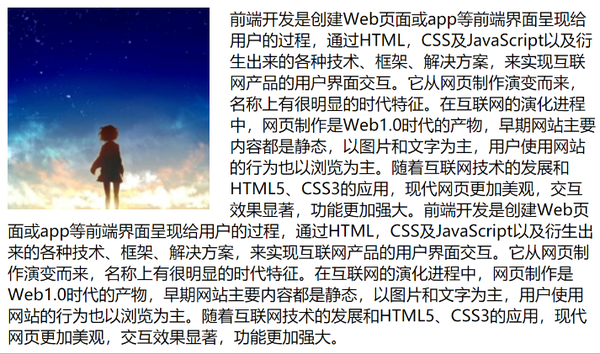

本课还用它实现网页布局，让原本垂直排列的块状区域横向排列，例如左侧栏与右侧内容区。

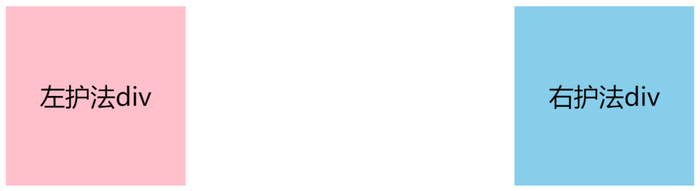

课程里“现在的作用”指本课采用浮动完成网页布局这一用途。下面按原课学习这一套排版方法。


### 4.2 float 的写法与课堂当前效果

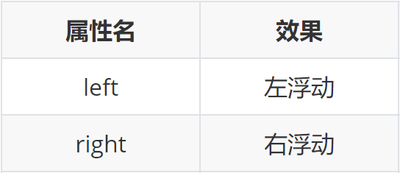

```css
.left {
    float: left;
}

.right {
    float: right;
}
```

`left` 表示向左浮动，`right` 表示向右浮动。浮动以当前包含区域的可用空间为依据，不是所有浮动元素都贴到浏览器窗口两端。

文件：`01-案例/06-体验-浮动.html`。下面保留原 CSS，以及当前启用的“网页布局”HTML 部分；文件前半段已注释的重复填充文字省略。

CSS（放在 `<style>` 内）：

```css
/* img {
    float: left;
} */

div {
    width: 100px;
    height: 100px;
}

.one {
    background-color: pink;
    float: left;
}

.two {
    background-color: skyblue;
    /* flr */
    /* float: right; */
    float: left;
}
```

HTML（放在 `<body>` 内）：

```html
<!-- 2. 网页布局: 块在一行排列 -->
<div class="one">one</div>
<div class="two">two</div>
```

当前 `.one`、`.two` 都是 `float: left`，因此空间足够时两个100×100px方块依次靠左排列。`.two` 的 `float: right` 已被注释；练习左右分栏时，用它替换当前的 `float: left`，第二块才会向右浮动。

原文件另有图文环绕演示，图片标签为：

```html
<img src="./images/1.jpg" alt="">
```

这张图片与后面的大段文字在 HTML 注释中，CSS 中的 `img { float: left; }` 也已注释。因此打开当前文件不会出现图文环绕。练习这一效果时，应同时恢复图片及文字和对应的图片浮动样式；素材位于 `01-案例/images/1.jpg`，尺寸200×200px。


### 4.3 浮动元素的特点与边界

1. **脱离标准流，在原来的标准流位置不占位。** 后续普通流块盒子不会为它保留原本的那一块布局空间。
2. 课程用“比标准流高半个级别”描述覆盖效果。浮动盒子可以覆盖普通流盒子的背景区域，但普通流文字会围绕浮动排列。这个比喻不是一个可以填写的 `z-index` 数值，也不是所有文字都会被遮住。
3. “浮动找浮动”：同向浮动的后续盒子会寻找相邻的可用位置；同一行放不下时会向下寻找位置。计算能否放下时，要把宽度、边框、内边距和水平外边距都考虑进去。
4. XMind 还强调：浮动会受到上方元素边界的影响。它不能任意穿过前面普通流元素或前面浮动元素的布局边界跑到顶部。
5. 浮动后可以一行显示多个盒子，也可以设置宽高。课程称其“具备行内块特点”，指这些显示能力，不代表实际 `display` 被设置成了 `inline-block`。

浮动盒子自身不能靠父级 `text-align: center` 或自己的 `margin: 0 auto` 实现水平居中。补充：浮动盒子内部的文字仍可以使用 `text-align: center`；要区分“盒子的位置”和“盒子里的文字位置”。


### 4.4 特点演示：两个浮动盒子与一个普通流盒子

文件：`01-案例/07-浮动-特点.html`。

CSS（放在 `<style>` 内）：

```css
/* 浮动的标签  顶对齐 */
/* 浮动: 在一行排列, 宽高生效 -- 浮动后的标签具备行内块特点 */
.one {
    width: 100px;
    height: 100px;
    background-color: pink;

    float: left;

    margin-top: 50px;
}

.two {
    width: 200px;
    height: 200px;
    background-color: skyblue;

    float: left;

    /* 因为有浮动, 不能生效 - 盒子无法水平居中 */
    margin: 0 auto;
}

.three {
    width: 300px;
    height: 300px;
    background-color: orange;
}
```

HTML（放在 `<body>` 内）：

```html
<div class="one">one</div>
<div class="two">two</div>
<div class="three">three</div>
```

| 盒子 | 当前设置 | 观察要点 |
| --- | --- | --- |
| `.one` | 100×100px，左浮动，`margin-top: 50px` | 可见盒子向下偏移50px |
| `.two` | 200×200px，左浮动，`margin: 0 auto` | 自动水平外边距不能把这个浮动盒子居中 |
| `.three` | 300×300px，没有浮动 | 仍按普通流布局，起始位置不为前两个浮动盒子保留空间 |

文件注释写有“浮动的标签顶对齐”，但当前 `.one` 已额外设置50px的上外边距，不能据此断言两个有色盒子的上边缘一样高。浮动位置还受外边距和可用空间影响。

普通流橙色盒子的背景可能出现在浮动盒子后面，其文字 `three` 则会避让浮动区域；水平空间不足时，文字可能被排到浮动区域下方。这同时说明“脱标”与“文字环绕”能够一起发生。


### 4.5 网页布局案例：通栏、版心与左右分区

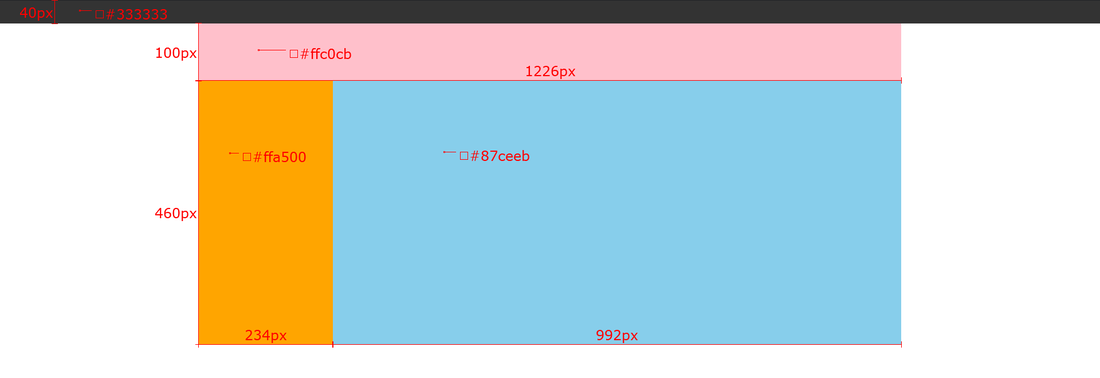

文件：`01-案例/08-综合案例-小米布局.html`。

布局从上往下、从外往内拆分：顶部通栏 `.top`，居中头部 `.header`，居中主体 `.content`，主体内部再放 `.left` 与 `.right`。

| 区域 | 宽高 | 排列方式 |
| --- | --- | --- |
| `.top` | 不指定固定宽度，高40px | 普通块盒子形成通栏 |
| `.header` | 1226×100px | `margin: 0 auto` 让普通流版心居中 |
| `.content` | 1226×460px | 普通流版心居中 |
| `.left` | 234×460px | 左浮动 |
| `.right` | 992×460px | 左浮动，紧接左区 |

`234 + 992 = 1226`，这一版左右两区恰好填满主体宽度，没有额外间隙。

CSS（放在 `<style>` 内）：

```css
* {
    margin: 0;
    padding: 0;
}

.top {
    /* 宽度高度背景色 */
    height: 40px;
    background-color: #333;
}

.header {
    width: 1226px;
    height: 100px;
    background-color: #ffc0cb;
    margin: 0 auto;
}

.content {
    width: 1226px;
    height: 460px;
    background-color: green;
    margin: 0 auto;
}

.left {
    float: left;

    width: 234px;
    height: 460px;
    background-color: #ffa500;


}

.right {
    float: left;

    width: 992px;
    height: 460px;
    background-color: #87ceeb;


}

/* CSS书写顺序: 浏览器执行效率更高
    1. 浮动 / display
    2. 盒子模型: margin border padding 宽度高度背景色
    3. 文字样式
*/
```

HTML（放在 `<body>` 内）：

```html
<!-- 通栏的盒子: 宽度和浏览器宽度一样大 -->
<div class="top"></div>
<div class="header">头部</div>
<div class="content">
    <div class="left">left</div>
    <div class="right">right</div>
</div>
```

原代码把声明分为“浮动/display → 盒子模型 → 文字样式”。这个顺序方便检查布局相关属性，可以作为本课的书写习惯；注释中“浏览器执行效率更高”的说法不宜当成性能结论，单纯调整这些声明的先后并不能保证渲染更快。

观察时先确认通栏与居中版心的区别，再确认两个子盒子并排。父盒子已经有460px固定高度，因此此处不依赖浮动子元素来撑出父级高度。


### 4.6 小米模块：先算宽度，再排两行卡片

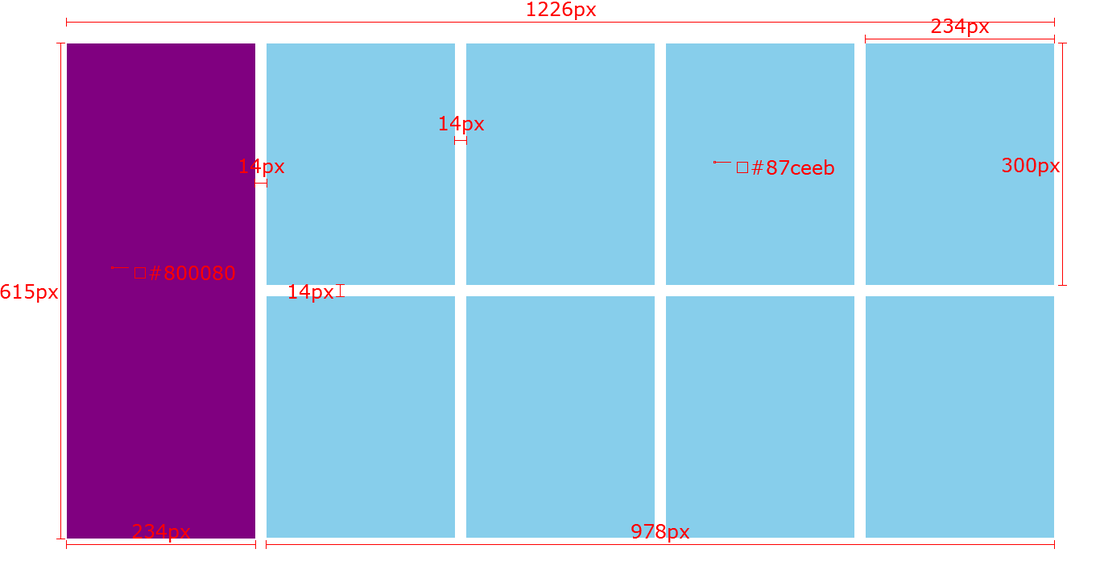

文件：`01-案例/09-综合案例-小米产品.html`。左侧一个长盒子，右侧8张卡片分成两行，每行4张。

| 部分 | 计算与尺寸 |
| --- | --- |
| 总版心 | 1226×614px |
| 左侧 | 234×614px，紫色 `#800080` |
| 右侧 | 978×614px |
| 左右之间 | `1226 - 234 - 978 = 14px` |
| 每张卡片 | 234×300px，天蓝色 `#87ceeb` |
| 一行宽度 | `234 × 4 + 14 × 3 = 978px` |
| 两排可见高度 | `300 × 2 + 14 = 614px` |

原作业 PNG 左边高度标注有残留叠字，显示为615px；课件第25页、课堂与必做源码均使用614px。本篇按源码及两排高度公式理解尺寸，保留原图供对照。

CSS（放在 `<style>` 内）：

```css
* {
    margin: 0;
    padding: 0;
}

.box {
    margin: 0 auto;

    width: 1226px;
    height: 614px;
    /* background-color: pink; */
}

.left {
    float: left;

    width: 234px;
    height: 614px;
    background-color: #800080;
}

.right {
    float: right;

    width: 978px;
    height: 614px;
    /* background-color: green; */
}

ul {

    /* 去掉列表的符号 */
    list-style: none;
}

.right li {
    float: left;

    margin-right: 14px;
    margin-bottom: 14px;

    width: 234px;
    height: 300px;
    background-color: #87ceeb;
}

/* 如果父级的宽度不够, 子级会自动换行 */
/* 第四个li和第八个li右侧间距清除 */
.right li:nth-child(4n) {
    margin-right: 0;
}
```

HTML（放在 `<body>` 内）：

```html
<div class="box">
    <div class="left"></div>
    <div class="right">
        <ul>
            <li></li>
            <li></li>
            <li></li>
            <li></li>
            <li></li>
            <li></li>
            <li></li>
            <li></li>
        </ul>
    </div>
</div>
```

左区向左浮动，右区向右浮动，二者之间自然留下14px。右区内部使用 `ul > li`，列表项向左浮动。

如果每张卡片都保留14px右外边距，一行需要 `(234 + 14) × 4 = 992px`，超出右区978px，第4张会换行。因此 `.right li:nth-child(4n)` 要把第4、8张卡片的右外边距改为0。

当前课堂版只去掉每行末尾的右外边距，没有去掉第二排的14px下外边距。614px是两排卡片本体和中间间距的高度，不能说它还把最后一排的下外边距也包在其中。父盒子有固定高度，第二排的这段外边距仍然存在；必做版本进一步处理它。


### 4.7 必做：小米模块完整 HTML

目标文件：`04-作业/01-综合案例（必做）/01-（案例）综合案例1-小米模块案例/01-（案例）综合案例1-小米模块案例.html`。

必做源码把右区卡片改为8个直接子级 `.item`，并加入 `:nth-child(n+5)`。这里的第5至8个孩子正好是第二排卡片。

```html
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <style>
    /* 去除掉标签默认的margin和padding */
    * {
      margin: 0;
      padding: 0;
    }
    
    .box {
      width: 1226px;
      height: 614px;
      /* background-color: pink; */
      margin: 100px auto;
    }

    .left {
      float: left;
      width: 234px;
      height: 614px;
      background-color: #800080;
    }

    .right {
      float: right;
      width: 978px;
      height: 614px;
      /* background-color: yellow; */
    }

    .item {
      float: left;
      width: 234px;
      height: 300px;
      background-color: #87ceeb;
      margin-right: 14px;
      margin-bottom: 14px;
    }

    /* 找到的是 第 4 和第 8个 4倍数  4n */
    .item:nth-child(4n) {
      /* background-color: red; */
      margin-right: 0;
    }

    /* 找到从第5个开始往后的所有个子元素 */
    .item:nth-child(n+5) {
      margin-bottom: 0;
    }
  </style>
</head>
<body>
  <!-- 布局流程：从上往下，从外往内 -->
  <div class="box">
    <div class="left"></div>
    <div class="right">
      <div class="item"></div>
      <div class="item"></div>
      <div class="item"></div>
      <div class="item"></div>
      <div class="item"></div>
      <div class="item"></div>
      <div class="item"></div>
      <div class="item"></div>
    </div>
  </div>
</body>
</html>
```

验证时看三个位置：每行有4张卡片；左右区域之间和卡片之间是14px；右侧第二排卡片底边与左侧紫色盒子底边对齐，第二排没有额外下外边距。`.box` 的 `margin: 100px auto` 还让整个模块距上方100px、水平居中。

补充：`.item:nth-child(...)` 在所有元素兄弟中计数，不是只在 `.item` 中计数。当前 `.right` 的直接孩子全是 `.item`，所以公式正好对应卡片；若插入标题等其他元素，应重新检查位置。


### 4.8 网页导航：让列表横排，让整块链接可点击

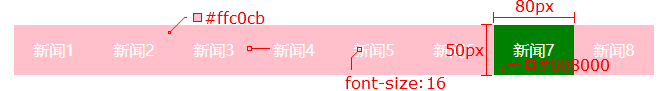

设计需求是8个80×50px导航项，总宽640px；背景粉色，文字白色、居中，鼠标悬停时背景变为绿色。

课件给出四步：

1. 清除标签默认的 `margin` 和 `padding`。
2. 给 `ul` 设置 `list-style: none`，去除列表符号。
3. 给 `li` 设置浮动，让列表项同一行显示。
4. 给 `a` 设置宽高与文字样式。`a` 默认是行内元素，必须先处理其显示方式。

课件列出的 `a` 方案有 `display: inline-block`、`display: block` 或 `float: left`。当前课堂文件 `01-案例/10-综合案例-导航.html` 采用 `display: block`：

CSS（放在 `<style>` 内）：

```css
* {
    margin: 0;
    padding: 0;
}

.nav {
    margin: 50px auto;
    width: 640px;
    height: 50px;
    background-color: #ffc0cb;
}

ul {
    list-style: none;
}

.nav li {
    float: left;
}

.nav li a {
    /* 1. 浮动 / display */
    /* display: inline-block; */
    display: block;

    /* 2. 盒子模型 */
    width: 80px;
    height: 50px;
    /* background-color: green; */

    /* 3. 文字样式 */
    text-align: center;
    line-height: 50px;
    color: #fff;
    text-decoration: none;
}

.nav li a:hover {
    background-color: green;
}
```

HTML（放在 `<body>` 内）：

```html
<!-- 导航 -->
<div class="nav">
    <ul>
        <li><a href="#">新闻</a></li>
        <li><a href="#">新闻</a></li>
        <li><a href="#">新闻</a></li>
        <li><a href="#">新闻</a></li>
        <li><a href="#">新闻</a></li>
        <li><a href="#">新闻</a></li>
        <li><a href="#">新闻</a></li>
        <li><a href="#">新闻</a></li>
    </ul>
</div>
```

`.nav` 是640×50px的普通流盒子，通过 `margin: 50px auto` 居中。内部 `li` 浮动，链接转成块盒子后，80×50px的整块区域都可点击和触发悬停颜色；`line-height: 50px` 实现单行文字垂直居中。

这里 `text-align: center` 控制的是链接内部文字，符合前面“浮动盒子不能靠它自身居中，但内部文字可以居中”的区别。当前课堂版没有显式设置字号；下面必做版按设计写了16px。


### 4.9 必做：网页导航完整 HTML

目标文件：`04-作业/01-综合案例（必做）/02-（案例）综合案例2-网页导航案例/02-（案例）综合案例2-网页导航案例.html`。

此版启用的是链接自身 `float: left`，两种 `display` 方案仍保留在注释里。不要同时把注释中的所有方案都当成当前启用代码。

```html
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <style>
    /* 1、去除标签默认的margin和padding */
    * {
      margin: 0;
      padding: 0;
    }

    /* 2、找到ul，去除小圆点 */
    ul{
      list-style: none;
    }

    /* 3、找到li标签，设置浮动 */
    ul li {
      float: left;
    }

    /* 4、找到a标签，设置宽高 */
    ul li a {
      /* a标签默认是行内元素，不能直接设置宽高 */
      /* 1、转换成行内块元素 */
      /* display: inline-block; */

      /* 2、转换成块级元素 */
      /* display: block; */

      /* 3、设置浮动 */
      float: left;

      width: 80px;
      height: 50px;
      background-color: #ffc0cb;
      text-decoration: none;
      text-align: center;
      line-height: 50px;
      color: #fff;
      font-size: 16px;
    }

    ul li a:hover {
      background-color: #008000;
    }
  </style>
</head>
<body>
  <ul>
    <li><a href="#">新闻1</a></li>
    <li><a href="#">新闻2</a></li>
    <li><a href="#">新闻3</a></li>
    <li><a href="#">新闻4</a></li>
    <li><a href="#">新闻5</a></li>
    <li><a href="#">新闻6</a></li>
    <li><a href="#">新闻7</a></li>
    <li><a href="#">新闻8</a></li>
  </ul>
</body>
</html>
```

验证时依次检查横向排列、单项80×50px、白色16px文字，以及悬停背景 `#008000`。窗口太窄时，浮动项可能换行。

这一版没有课堂文件的 `.nav` 外层，也没有给 `ul` 设置高度或清除浮动。`li` 全部浮动时，普通流的 `ul` 不能靠它们撑出高度；继续在后面增加其他页面内容时，会遇到下一章讨论的影响。


## 5. 清除浮动

清除浮动的含义是清除浮动带来的布局影响。浮动本身仍然用于横排，重点是让父级获得需要的高度，使后续普通流内容出现在正确的位置。


### 5.1 为什么父盒子没有被浮动子元素撑开

文件：`01-案例/11-受浮动影响的情况.html`。

CSS（放在 `<style>` 内）：

```css
.top {
    margin: 0 auto;
    width: 1000px;
    /* height: 300px; */
    background-color: pink;
}

.bottom {
    height: 100px;
    background-color: green;
}

.left {
    float: left;
    width: 200px;
    height: 300px;
    background-color: #ccc;
}

.right {
    float: right;
    width: 790px;
    height: 300px;
    background-color: skyblue;
}
```

HTML（放在 `<body>` 内）：

```html
<!-- 父子级标签, 子级浮动, 父级没有高度, 后面的标准流盒子会受影响, 显示到上面的位置 -->
<div class="top">
    <div class="left"></div>
    <div class="right"></div>
</div>
<div class="bottom"></div>
```

`.top` 宽1000px，没有启用固定高度；内部左区200×300px向左浮动，右区790×300px向右浮动，中间剩10px。父级既没有普通流内容撑高，也没有建立后面介绍的包含浮动的布局环境，因此其内容高度为0。

后面的 `.bottom` 是100px高的普通流绿色盒子。它根据 `.top` 在标准流中的高度排位置，因而上移到父级开始的区域，绿色背景可能显示在浮动盒子后面或周围。

练习时用 Chrome 检查 `.top` 的盒模型高度，再分别加入下文的一种方法。处理后应能看到父级高度达到300px，`.bottom` 出现在左右区域的下方。这里给的是代码分析与操作预期，不是 Notebook 的执行输出。

补充：这个问题有前提——父级是普通流块盒子、没有固定高度，且浮动子元素没有被父级的其他机制包含。并非“任何父元素只要有浮动孩子就必然高度为0”。


### 5.2 方法一：直接设置父元素高度

在上面的 `11-受浮动影响的情况.html` 中，取消 `.top` 的 `height: 300px;` 注释即可：

```css
.top {
    margin: 0 auto;
    width: 1000px;
    height: 300px;
    background-color: pink;
}
```

父级在普通流中占300px高度，后面的 `.bottom` 就排在它之后。左右子元素继续浮动，不需要取消 `float`。

原课评价：简单、方便，但某些布局不能固定高度。例如新闻条数、推荐商品数量或文字长度会变化，写死父高度可能留下空白，或让内容超出盒子。前面固定尺寸的小米模块可以直接给高度，这类动态内容则需要其他方法。


### 5.3 方法二：额外标签法

操作是在**父元素内部、所有浮动子元素之后**添加一个块级空标签，并设置 `clear: both`。

文件：`01-案例/12-清除浮动-额外标签法.html`。

CSS（放在 `<style>` 内）：

```css
.top {
    margin: 0 auto;
    width: 1000px;
    /* height: 300px; */
    background-color: pink;
}

.bottom {
    height: 100px;
    background-color: green;
}

.left {
    float: left;
    width: 200px;
    height: 300px;
    background-color: #ccc;
}

.right {
    float: right;
    width: 790px;
    height: 300px;
    background-color: skyblue;
}

.clearfix {
    /* 清除左右两侧浮动的影响 */
    clear: both;
}
```

HTML（放在 `<body>` 内）：

```html
<!-- 父子级标签, 子级浮动, 父级没有高度, 后面的标准流盒子会受影响, 显示到上面的位置 -->
<div class="top">
    <div class="left"></div>
    <div class="right"></div>
    <div class="clearfix"></div>
</div>
<div class="bottom"></div>
```

`.clearfix` 是普通流的块盒子，`clear: both` 让它避开前面左右两侧的浮动区域，排到浮动盒子下方。这个辅助盒子仍在 `.top` 内部，所以父级自动高度能延伸到需要的位置。

不能把它放到父级外面再声称“撑开了原来的父盒子”；位置是方法的一部分。原课指出的缺点是每处都要增加一个仅供布局使用的 HTML 标签，让结构变复杂。


### 5.4 方法三：单伪元素清除法

用父级的 `::after` 替代上一节的空标签，在父级内容最后生成辅助盒子。给需要处理的父盒子添加 `clearfix` 类。

原课基本写法：

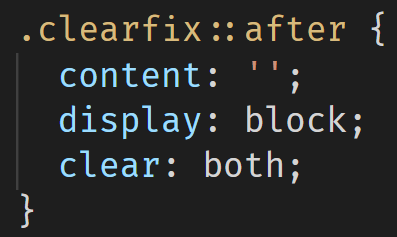

原课补充写法：

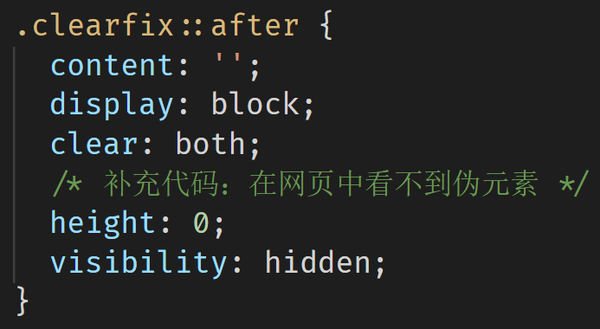

文件：`01-案例/13-清除浮动-单伪元素.html`。

CSS（放在 `<style>` 内）：

```css
.top {
    margin: 0 auto;
    width: 1000px;
    /* height: 300px; */
    background-color: pink;
}

.bottom {
    height: 100px;
    background-color: green;
}

.left {
    float: left;
    width: 200px;
    height: 300px;
    background-color: #ccc;
}

.right {
    float: right;
    width: 790px;
    height: 300px;
    background-color: skyblue;
}

/* 单伪元素清除浮动 和 额外标签法原理是一样的 */
.clearfix::after {
    content: '';

    /* 伪元素添加的标签是行内, 要求块 */
    display: block;
    clear: both;

    /* 为了兼容性 */
    height: 0;
    visibility: hidden;
}
```

HTML（放在 `<body>` 内）：

```html
<!-- 父子级标签, 子级浮动, 父级没有高度, 后面的标准流盒子会受影响, 显示到上面的位置 -->
<div class="top clearfix">
    <div class="left"></div>
    <div class="right"></div>
    <!-- 通过css 添加标签 -->
</div>
<div class="bottom"></div>
```

核心三句分别承担不同作用：`content: ''` 生成伪元素，`display: block` 让它成为块盒子，`clear: both` 让它避开前面的左右浮动。单纯生成一个默认行内伪元素，不能完成这里的清除方法。

课堂还保留 `height: 0`、`visibility: hidden`，使辅助盒子没有可见高度、内容不可见；源码将它们归为兼容性的补充。不要把 `visibility: hidden` 当成清除浮动的核心属性。

`class="top clearfix"` 写在父级上；不是给每个浮动孩子加 `clearfix`。完成后父级自动高度能包含两侧300px高的区域，后面的绿色盒子移到下方。


### 5.5 方法四：双伪元素清除法

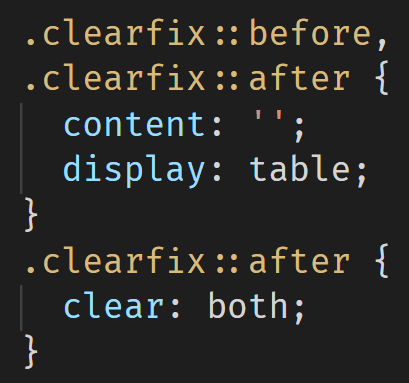

文件：`01-案例/14-清除浮动-双伪元素.html`。

CSS（放在 `<style>` 内）：

```css
.top {
    margin: 0 auto;
    width: 1000px;
    /* height: 300px; */
    background-color: pink;
}

.bottom {
    height: 100px;
    background-color: green;
}

.left {
    float: left;
    width: 200px;
    height: 300px;
    background-color: #ccc;
}

.right {
    float: right;
    width: 790px;
    height: 300px;
    background-color: skyblue;
}

/*  .clearfix::before 作用: 解决外边距塌陷问题
    外边距塌陷: 父子标签, 都是块级, 子级加margin会影响父级的位置
*/
/* 清除浮动 */
.clearfix::before,
.clearfix::after {
    content: '';
    display: table;
}

/* 真正清除浮动的标签 */
.clearfix::after {
    /* content: '';
    display: table; */
    clear: both;
}
```

HTML（放在 `<body>` 内）：

```html
<!-- 父子级标签, 子级浮动, 父级没有高度, 后面的标准流盒子会受影响, 显示到上面的位置 -->
<div class="top clearfix">
    <div class="left"></div>
    <div class="right"></div>
</div>
<div class="bottom"></div>
```

共同规则给 `::before`、`::after` 设置空内容和 `display: table`；只给 `::after` 设置 `clear: both`，因此真正承担清除浮动的是末尾伪元素。

原课还用前面的 `::before` 处理父子块盒子的外边距塌陷：生成的辅助盒子隔开相应边界，避免子元素上外边距把父级一起推走。这与第05天的父子 `margin` 塌陷问题相连。

这里兼顾的是父子边界的塌陷，不能概括成“加上双伪元素后，页面中所有外边距合并都消失”。当前示例的孩子是浮动盒子，主要用于观察清除浮动；其附带的塌陷处理作用要结合普通流父子场景理解。


### 5.6 方法五：给父元素设置 overflow: hidden

文件：`01-案例/15-清除浮动-overflow.html`。这次没有额外标签，也没有伪元素，直接在父级 `.top` 上设置 `overflow: hidden`：

CSS（放在 `<style>` 内）：

```css
.top {
    margin: 0 auto;
    width: 1000px;
    /* height: 300px; */
    background-color: pink;

    overflow: hidden;
}

.bottom {
    height: 100px;
    background-color: green;
}

.left {
    float: left;
    width: 200px;
    height: 300px;
    background-color: #ccc;
}

.right {
    float: right;
    width: 790px;
    height: 300px;
    background-color: skyblue;
}
```

HTML（放在 `<body>` 内）：

```html
<!-- 父子级标签, 子级浮动, 父级没有高度, 后面的标准流盒子会受影响, 显示到上面的位置 -->
<div class="top">
    <div class="left"></div>
    <div class="right"></div>
</div>
<div class="bottom"></div>
```

父级仍未启用固定高度，但可以把内部浮动盒子计入自动高度；后面的绿色盒子因此排到父级下方。原课将它的优点概括为方便，原理与下一节的 BFC 有关。

补充：`overflow: hidden` 还会裁剪盒子外的溢出内容。设计中若存在需要露在外面的内容，要同时考虑这一效果，不能只看到它解决了父高度问题。


### 5.7 原课拓展：BFC 与包含浮动

**BFC** 是块格式化上下文（Block Formatting Context）。课件把它解释为块盒子布局、浮动与其他元素交互发生的区域；初学时可以理解为一块有独立布局规则的区域。

课件列出的创建方式：

| 情况 | 本课中的写法或对象 |
| --- | --- |
| 根元素 | `html` 所建立的布局区域 |
| 浮动元素 | 设置 `float: left` 或 `float: right` |
| 行内块元素 | `display: inline-block` |
| 特定的溢出处理 | 本课使用 `overflow: hidden`，也列出 `auto` |

原课对 `overflow` 简写为“取值不为 visible”。补充：本课可掌握的常见值是 `hidden`、`auto`、`scroll`；不要把这个简写当成对任意值都成立的判定公式。

本课强调两个特点：

1. 建立 BFC 的盒子在计算自动高度时，可以包含内部浮动子元素。因此给前例父级设置 `overflow: hidden` 后，父级能够撑到浮动子元素底部。
2. 建立 BFC 的盒子与其普通流子元素之间不会发生跨边界的垂直外边距塌陷，因此也可用于处理第05天讲的父子外边距问题。

第二点不表示区域内部所有相邻兄弟的外边距都不会合并；讨论的是父盒子与子元素之间的边界。第一点也不表示显式设置的固定高度会自动变大，前例依靠的是父级的自动高度。


### 5.8 对照五种方法，确认改的是哪里

| 方法 | 修改位置 | 原课侧重点 |
| --- | --- | --- |
| 固定高度 | 父盒子的 `height` | 简单；内容高度变化时不适合写死 |
| 额外标签 | 父级内部最后一个块标签，`clear: both` | 原理直接；增加 HTML 标签 |
| 单伪元素 | 父级加 `clearfix`，在 `::after` 清除 | 把额外标签交给 CSS 生成 |
| 双伪元素 | 父级加 `clearfix`，前后生成辅助盒子 | `::after` 清浮动，兼顾父子外边距塌陷 |
| `overflow: hidden` | 父盒子的 `overflow` | 方便；需留意溢出内容被裁剪 |

练习时一次采用一种方法，再检查父高度和后续盒子的位置。它们的共同目标是清除浮动对子元素容纳、后续布局的影响，不是把两侧子元素的 `float` 删除。


## 6. 课后选做与练习

两项必做已随对应课堂案例整理在第4章。下面保留本日选做资料：微金所导航，以及尚合、腾讯云两个项目的设计图、素材与原文字。


### 6.1 微金所导航案例（★★★）

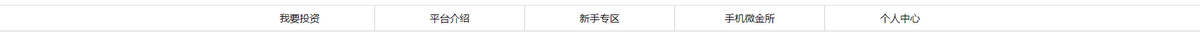

目标文件：`04-作业/02-作业（选做）/01-微金所导航案例★★★/微金所导航案例.html`。

需求是底边框横贯页面、导航内容在1200px版心内居中、5个项目均分宽度。外层 `.nav` 负责通栏底边框，内部 `ul` 负责版心，不能把两者的宽度职责混为一个盒子。

```html
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <style>
    * {
      margin: 0;
      padding: 0;
    }

    /* 因为有通栏：占满一行的边框，所以需要有一个通栏：占满一行的盒子 */
    .nav {
      height: 40px;
      border-bottom: 1px solid #ccc;
    }

    /* 因为ul中所有的内容都是在网页的宽度固定并且水平居中的盒子内部，所以设置ul为宽度固定并且水平居中的效果（后面项目中所用到的版心） */
    ul {
      list-style: none;
      width: 1200px;
      margin: 0 auto;
    }

    ul li {
      float: left;
      width: 20%;
      height: 40px;
      border-right: 1px solid #ccc;
      /* 自动内减 */
      box-sizing: border-box;
      text-align: center;
      line-height: 40px;
    }

    ul .last {
     border-right: none;
    }

    ul li a {
      /* a标签默认是行内元素，宽高由内容撑开，并且无法设置宽高，此时默认情况用户只能点击文字区域才能调整 */
      /* 如果把a标签转换成块级元素，此时可以设置宽高，会让a标签范围更大，用户可以点击调整的区域也越大 */
      display: block;
      /* 宽度不设置块元素会默认占满一行 */
      height: 40px;
      text-decoration: none;
      color: #000;
    }
  </style>
</head>
<body>
  <!-- 导航 -->
  <div class="nav">
    <ul>
      <li><a href="#">我要投资</a></li>
      <li><a href="#">平台介绍</a></li>
      <li><a href="#">新手专区</a></li>
      <li><a href="#" class="app">手机微金所</a></li>
      <li class="last"><a href="#">个人中心</a></li>
    </ul>
  </div>

</body>
</html>
```

每个 `li` 的宽度是 `1200 × 20% = 240px`。设置 `box-sizing: border-box` 后，1px右边框包含在240px以内，5项才不会因边框累加而超过1200px。源码通过最后一项的 `.last` 类去掉右边框。

`a` 转为块级后，不必额外指定宽度就可以占满列表项的内容宽度，40px高度也让整块链接区域可点击。原注释中的“点击调整”应理解为点击跳转；当前 `href="#"` 只是演示占位地址。

素材目录还有120×136px的 `images/code.jpg`，HTML 也给“手机微金所”链接保留 `.app` 类，但当前 CSS 没有实现二维码悬浮效果，也没有引用该图片。不要把未提供的交互当成案例已完成的功能。


### 6.2 尚合项目（★★★★★）：根据设计图拆布局

资料目录：`04-作业/02-作业（选做）/项目01-尚合项目★★★★★`。

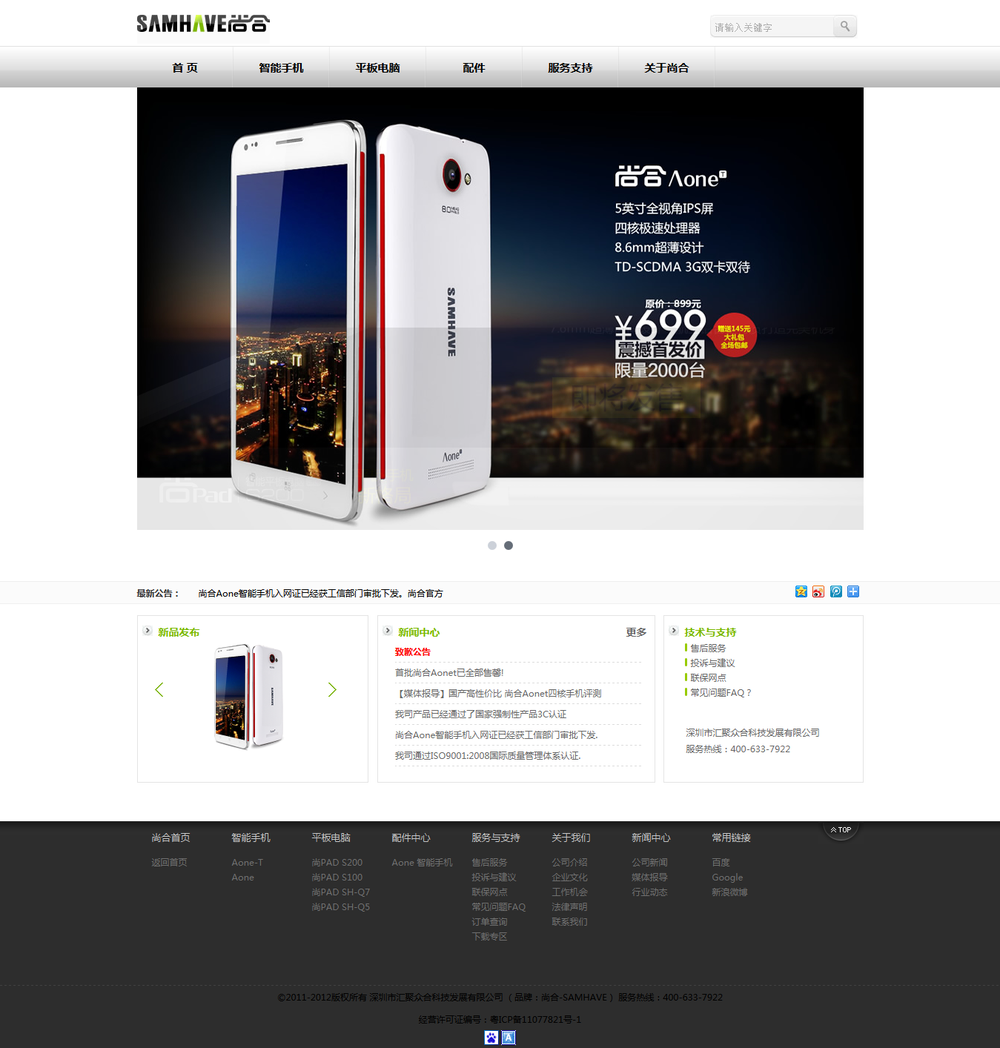

这份项目资料有 `尚合.png`、`文字.txt`、`说明.txt` 和 `images` 素材，**没有提供 HTML/CSS 源码**。下面按设计图记录练习需要识别的区域，不把自行推测的实现写成原课程答案。

从上往下观察：顶部标志与搜索框、6项导航、横幅、公告与分享区、三个内容区域（新品发布、新闻中心、技术与支持），最后是深色页脚中的8组栏目与版权文字。先确定外层版心，再拆分同排区域，综合使用盒子模型和浮动。

素材尺寸来自原文件，不能把图片尺寸直接当成所有显示盒子的尺寸：

| 素材 | 原始尺寸 | 对照区域 |
| --- | --- | --- |
| `images/logo.png` | 180×24px | 顶部标志 |
| `images/search.png` | 200×30px | 搜索框相关图 |
| `images/banner.png` | 980×666px | 横幅素材，显示方式按设计图判断 |
| `images/nav_bg.png`、`images/nav_border.png` | 1×55px、2×54px | 导航背景与分隔相关素材 |
| `images/share.png` | 86×16px | 公告右侧分享区域 |
| `images/shouji.png` | 111×148px | 新品展示 |
| `images/left_icon.png`、`images/right_icon.png` | 18×27px、17×27px | 左右方向图标 |
| `images/jiantou.png`、`images/sbg.png` | 14×13px、3×11px | 小箭头、列表标记等辅助素材 |
| `images/bottom_logo.png`、`images/top.png` | 42×19px、52×27px | 底部及返回顶部相关素材 |

原 `文字.txt` 保留如下，拼写沿用资料，可在练习中复制；其中“售馨”等文字是原素材内容：

```text
首 页
智能手机
平板电脑
配件
服务支持
关于尚合

最新公告：
尚合Aone智能手机入网证已经获工信部门审批下发。尚合官方
      
新品发布

新闻中心更多

致歉公告
首批尚合Aonet已全部售馨!
【媒体报导】国产高性价比 尚合Aonet四核手机评测
我司产品已经通过了国家强制性产品3C认证
尚合Aone智能手机入网证已经获工信部门审批下发.
我司通过ISO9001:2008国际质量管理体系认证.

技术与支持
售后服务
投诉与建议
联保网点
常见问题FAQ？
深圳市汇聚众合科技发展有限公司
服务热线：400-633-7922


尚合首页
返回首页

智能手机
Aone-T
Aone

平板电脑
尚PAD S200
尚PAD S100
尚PAD SH-Q7
尚PAD SH-Q5

配件中心
Aone 智能手机

服务与支持
售后服务
投诉与建议
联保网点
常见问题FAQ
订单查询
下载专区

关于我们
公司介绍
企业文化
工作机会
法律声明
联系我们

新闻中心
公司新闻
媒体报导
行业动态

常用链接
百度
Google
新浪微博

2011-2012版权所有 深圳市汇聚众合科技发展有限公司 （品牌：尚合-SAMHAVE） 服务热线：400-633-7922
经营许可证编号：粤ICP备11077821号-1
```

该目录的 `说明.txt` 将案例称作“腾讯云案例”，与文件夹及设计图不一致，属于复用说明中的名称差异；当前这份练习按“尚合项目”识别。说明要求先跟随视频模仿步骤，再重复练习，最终只看设计图也能完成。资料还提到后续课程的定位与小兔鲜项目，本篇不提前展开它们的实现。


### 6.3 腾讯云项目（★★★★★★）：通栏与版心的组合

资料目录：`04-作业/02-作业（选做）/项目02-腾讯云项目★★★★★★`。

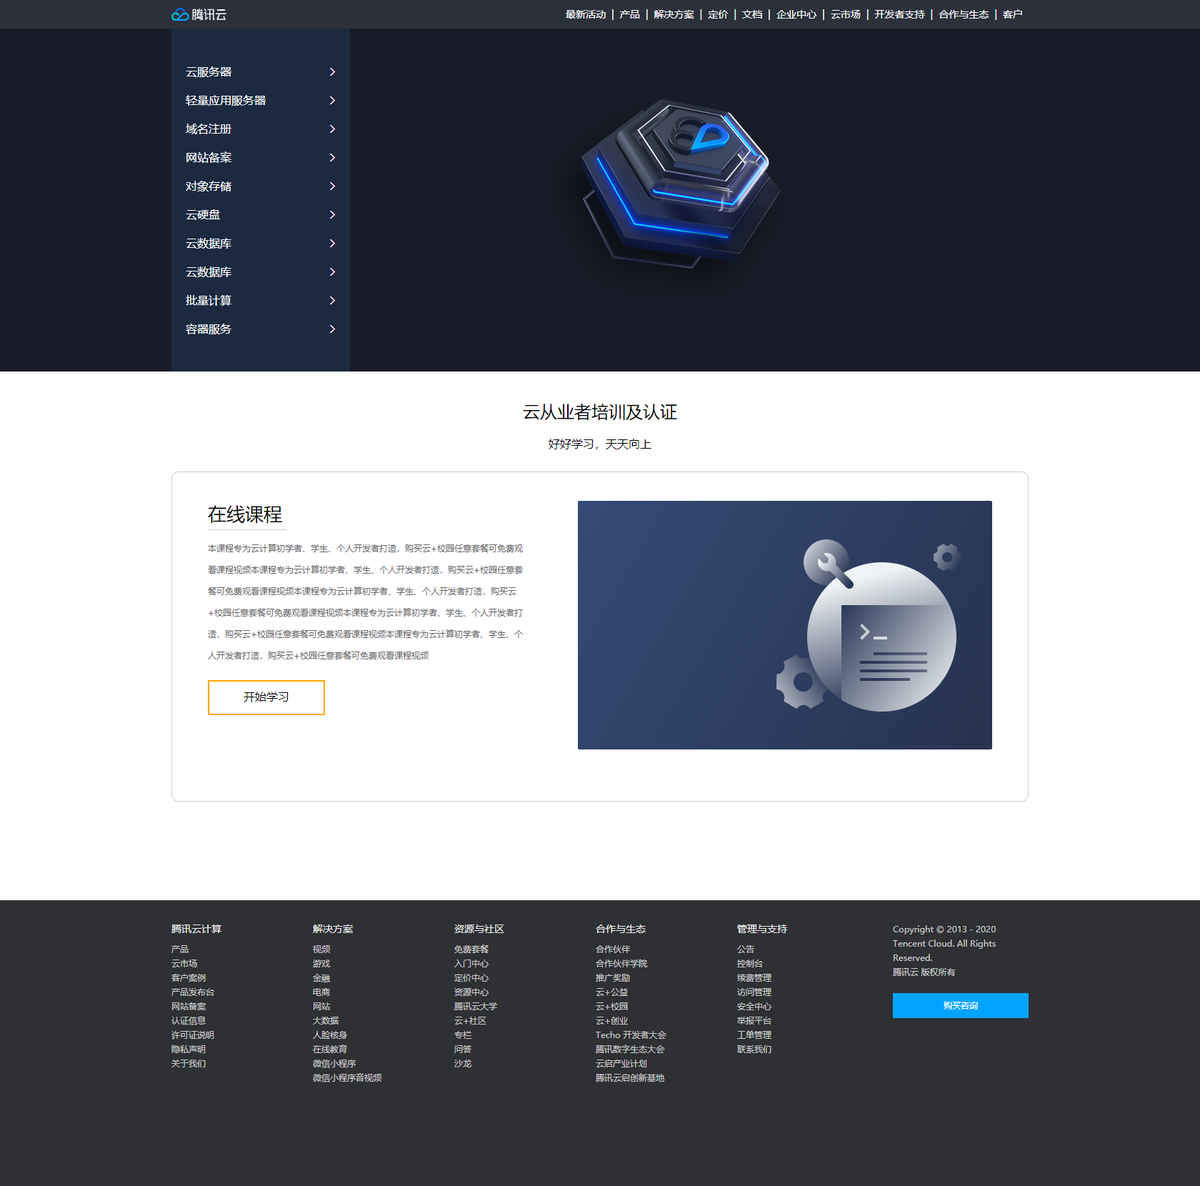

资料同样只有 `设计图.png`、`文字.txt`、`说明.txt` 和图片素材，没有现成的 HTML/CSS 答案。

设计图从上往下分为：标志与10项顶部导航；横幅区域中的左侧10项菜单与右侧主图；“云从业者培训及认证”标题及“在线课程”的左右图文区域；深色页脚的5组链接、版权与购买咨询。

| 素材 | 原始尺寸 |
| --- | --- |
| `images/logo.png` | 78×18px |
| `images/banner.png` | 1200×480px |
| `images/right.png` | 1160×696px |

练习时先区分通栏背景与内部固定宽度内容，再用浮动组织同排盒子。父级高度会随内容变化的区域，完成子级浮动后要检查是否需要清除影响。尺寸与间距应根据设计图量取，不用素材的原始尺寸代替所有布局尺寸。

原 `文字.txt` 如下。“在线课程”说明连续重复多遍是资料中的填充文本；这里保留原文供复现版面：

```text
最新活动
产品
解决方案
定价
文档
企业中心
云市场
开发者支持
合作与生态
客户

云服务器
轻量应用服务器
域名注册
网站备案
对象存储
云硬盘
云数据库
云数据库
批量计算
容器服务

云从业者培训及认证
好好学习，天天向上

在线课程

本课程专为云计算初学者、学生、个人开发者打造，购买云+校园任意套餐可免费观看课程视频本课程专为云计算初学者、学生、个人开发者打造，购买云+校园任意套餐可免费观看课程视频本课程专为云计算初学者、学生、个人开发者打造，购买云+校园任意套餐可免费观看课程视频本课程专为云计算初学者、学生、个人开发者打造，购买云+校园任意套餐可免费观看课程视频本课程专为云计算初学者、学生、个人开发者打造，购买云+校园任意套餐可免费观看课程视频

开始学习

腾讯云计算
产品
云市场
客户案例
产品发布台
网站备案
认证信息
许可证说明
隐私声明
关于我们

解决方案
视频
游戏
金融
电商
网站
大数据
人脸核身
在线教育
微信小程序
微信小程序音视频

资源与社区
免费套餐
入门中心
定价中心
资源中心
腾讯云大学
云+社区
专栏
问答
沙龙

合作与生态
合作伙伴
合作伙伴学院
推广奖励
云+公益
云+校园
云+创业
Techo 开发者大会
腾讯数字生态大会
云启产业计划
腾讯云启创新基地

管理与支持
公告
控制台
续费管理
访问管理
安全中心
举报平台
工单管理
联系我们

Copyright © 2013 - 2020

Tencent Cloud. All Rights Reserved.

腾讯云 版权所有

购买咨询
```

`说明.txt` 的练习要求与尚合项目相同：先跟视频完成，再多写几遍，逐渐脱离视频和老师代码，最后只根据设计图独立完成。项目中后续知识涉及的细节，留在对应课程学习。


### 6.4 本日练习顺序与目标检查

按原资料的学习流程，先梳理当天 PDF/XMind，再重复课堂代码，完成两项必做；有余力时选择1至2项选做练习。

检查自己能否完成本课目标：

1. 说明为什么 `a:first-child` 会匹配多个列表项里的链接，并写出第一个 `li` 中第3个 `a` 的选择器。
2. 用 `4n` 与 `n+5` 解释小米模块每行末尾、最后一排的外边距处理。
3. 说清普通块、行内块与浮动盒子的排列区别，避免把 `float` 当成 `display: inline-block`。
4. 按设计尺寸完成小米模块与导航，检查宽度和间距是否容纳得下。
5. 在父级自动高度的例子中指出浮动造成的影响，并分别用五种方法让后续盒子排在下方。

原资料要求课堂代码多练几遍，直到能独立写出；项目练习也以能够只看设计图完成为目标，而不是仅跟着写完一次。
